# Issue #206 — fixed-N7 constrained ticket policy

This thin notebook verifies the immutable package, renders the frozen chronological decision, and inspects the label-blind Stage-3 handoff. Core generation, modeling, settlement, and plotting live in `src/ticket_policy/fixed_n7.py`.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd

ROOT = Path.cwd().parents[2]
sys.path.insert(0, str(ROOT / 'src'))
from ticket_policy.fixed_n7 import verify

PACKAGE = ROOT / 'results' / 'issue-206'
verification = verify(PACKAGE)
decision = json.loads((PACKAGE / 'decision.json').read_text(encoding='utf-8'))
surface = pd.read_csv(PACKAGE / 'policy_surface.csv')
calibration = pd.read_csv(PACKAGE / 'ticket_calibration.csv')
requests = pd.read_parquet(PACKAGE / 'ticket_requests.parquet')
verification, decision

({'status': 'PASS',
  'files': 14,
  'manifest_sha256': '5b5683dfab1e40d39e0f85c9e38b3a06840577638037e9b51af05b340084ceb4',
  'request_rows': 600,
  'issues': 75},
 {'advance_learned_policy': False,
  'challenger_k': 8,
  'challenger_policy': 'LEARNED_MLP',
  'disposition': 'INHERIT_STRONGEST_FROZEN_CONTROL',
  'evaluation_split': 'CV_2023',
  'fallback_mixed_k': 8,
  'fallback_mixed_policy': 'MARKET_WR',
  'fallback_reason': 'VALIDATION_UNCERTAINTY_OR_MATCHED_LIFT_FLOOR',
  'label_embargo': 'No LOCKED_TEST (2025/2026) outcome or official-final-SP label enters training, selection, or evaluation',
  'matched_turnover': 928.0,
  'paired_validation_issues': 58,
  'safe_control_k': 8,
  'safe_control_policy': 'MARKET_WR',
  'selection_split': 'CV_2022',
  'stage_boundary': 'requested tickets and requested ¥2 stake only; no bankroll sizing authority',
  'validation_coverage_lift': 0.0,
  'validation_expected_lift': -68.68514632958649,
  'validation_lift_one_sided_95_lcb': -0.914040135113157

In [2]:
evaluation = surface.loc[(surface['split'] == 'CV_2023') & surface['stake_budget_matched'], [
    'policy', 'k', 'turnover', 'expected_pre_tax_net', 'realized_pre_tax_net',
    'coverage', 'match_overlap', 'repeat_share',
    'matched_lift_realized_pre_tax_net'
]].sort_values('realized_pre_tax_net', ascending=False)
evaluation, calibration.head(10)

(                       policy  k  turnover  expected_pre_tax_net  \
 36                 MARKET_WOR  8     880.0             76.204753   
 27                  BEST_FULL  8     880.0            131.827050   
 30  EXPERIMENTAL_MLP_ABLATION  8     880.0              4.423823   
 33                LEARNED_MLP  8     880.0              0.359653   
 39                  MARKET_WR  8     880.0             78.369429   
 42             OVERLAP_CAPPED  8     880.0            131.827050   
 45          OVERLAP_PENALIZED  8     880.0            131.827037   
 48            TEMPERATURE_050  8     880.0             55.047150   
 51            TEMPERATURE_100  8     880.0             78.076211   
 
     realized_pre_tax_net  coverage  match_overlap  repeat_share  \
 36             -0.857525  0.018182       0.178571      0.000000   
 27             -1.000000  0.000000       0.299629      0.000000   
 30             -1.000000  0.000000       0.052597      0.000000   
 33             -1.000000  0.000000 

In [3]:
handoff_receipt = {
    'issues': int(requests['issue'].nunique()),
    'requested_tickets': int(len(requests)),
    'requested_stake_yuan': int(requests['requested_stake'].sum()),
    'all_n_exactly_7': bool(requests['n'].eq(7).all()),
    'labels_used': bool(requests['labels_used'].any()),
    'fallback_share': float(requests['fallback_applied'].mean()),
    'repeat_ticket_rows': int(requests.duplicated(['issue', 'ticket_identity']).sum()),
}
handoff_receipt, requests.head(8)[['issue', 'ticket_identity', 'policy', 'requested_stake', 'fallback_reason']]

({'issues': 75,
  'requested_tickets': 600,
  'requested_stake_yuan': 1200,
  'all_n_exactly_7': True,
  'labels_used': False,
  'fallback_share': 1.0,
  'repeat_ticket_rows': 44},
    issue                            ticket_identity     policy  \
 0  25043   54:3|118:3|212:3|321:3|327:3|351:3|457:3  MARKET_WR   
 1  25043  121:3|208:3|212:3|215:3|344:1|353:1|370:3  MARKET_WR   
 2  25043    52:3|70:3|207:3|208:3|225:3|348:0|402:3  MARKET_WR   
 3  25043   82:3|118:3|153:0|211:0|220:3|262:3|402:3  MARKET_WR   
 4  25043     52:3|60:3|70:3|196:3|211:0|324:0|402:3  MARKET_WR   
 5  25043   34:3|118:3|155:3|207:3|212:3|262:3|405:3  MARKET_WR   
 6  25043   63:1|115:3|256:3|346:3|379:3|461:3|463:1  MARKET_WR   
 7  25043      31:3|34:3|48:0|82:3|260:0|385:1|405:3  MARKET_WR   
 
    requested_stake                               fallback_reason  
 0                2  VALIDATION_UNCERTAINTY_OR_MATCHED_LIFT_FLOOR  
 1                2  VALIDATION_UNCERTAINTY_OR_MATCHED_LIFT_FLOOR  
 2        

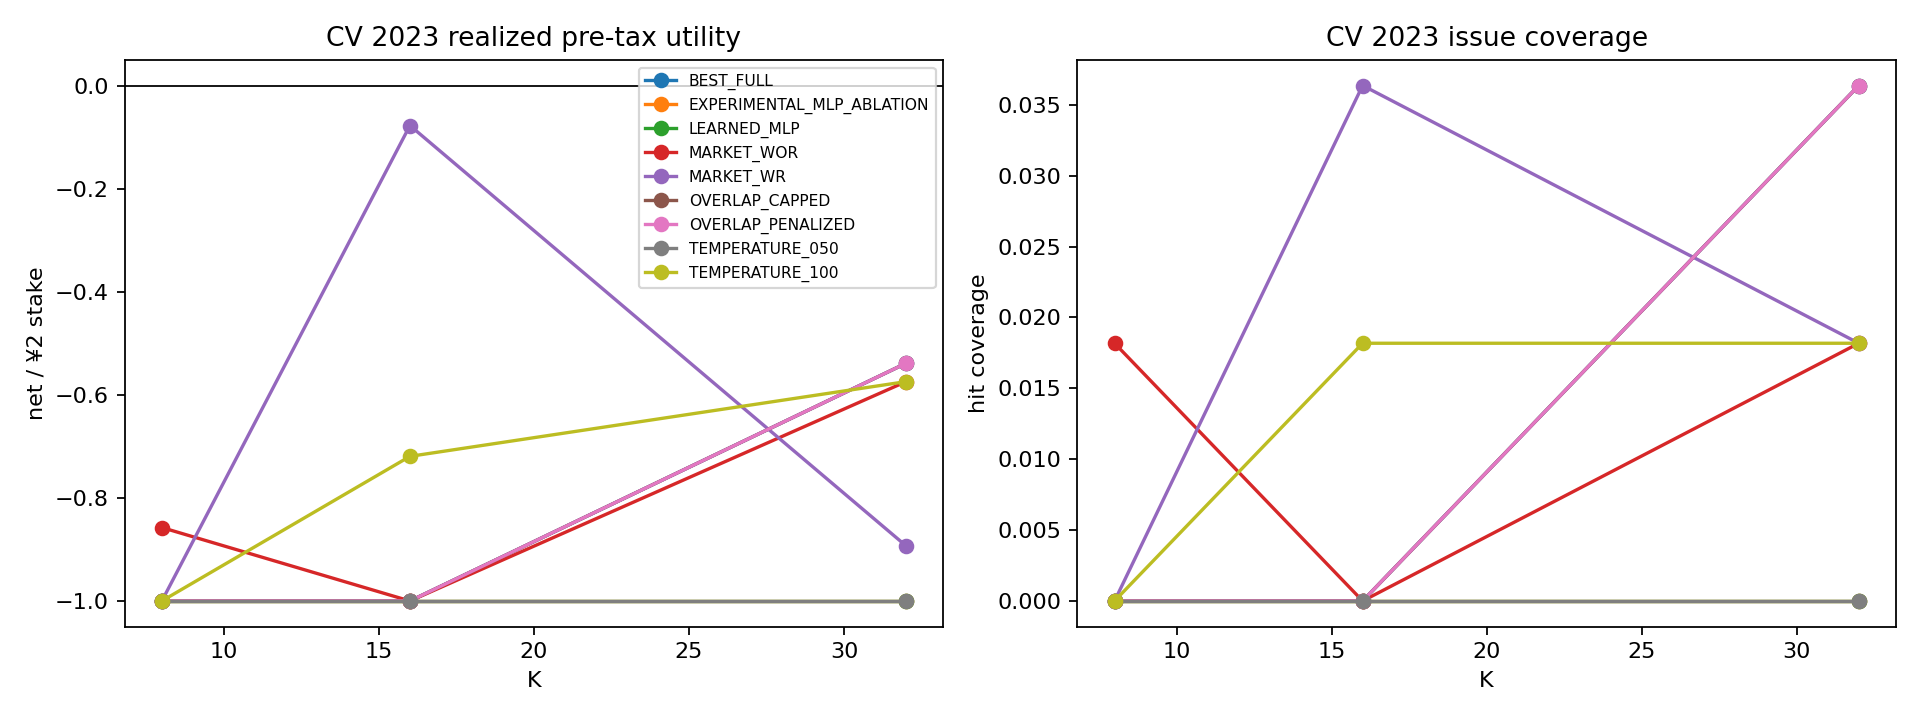

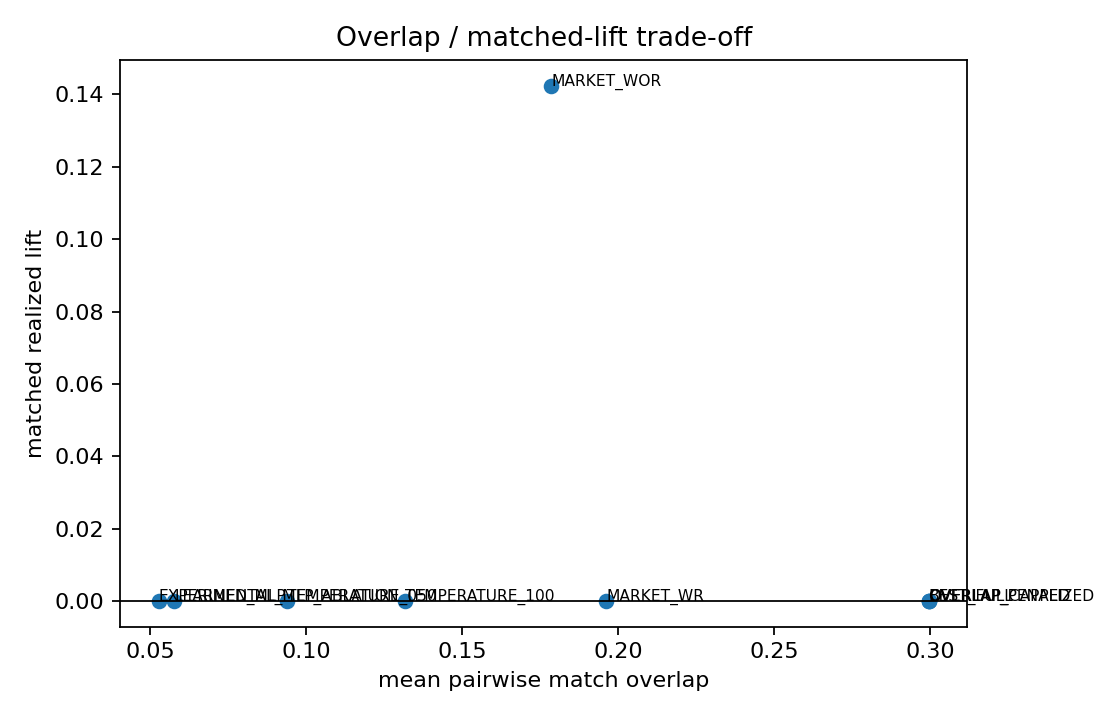

In [4]:
from IPython.display import Image, display
display(Image(filename=str(PACKAGE / 'policy_surface.png')))
display(Image(filename=str(PACKAGE / 'overlap_lift.png')))